In [1]:
import pandas as pd
import pickle
from sklearn.ensemble import RandomForestRegressor
from hyperopt import space_eval,hp
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

/home/mbreed/.local/share/mamba/envs/data_science/lib/python3.13/site-packages/hyperopt/atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
def eeip_mapping(nucleotide_sequence):

    new_rep = []

    mapping = {'T' : 0.1335,
              'C' : 0.1340,
              'A' : 0.1260,
              'G' : 0.0806}

    for nt in nucleotide_sequence:
        nt_transform = mapping[nt]
        new_rep.append(nt_transform)

    return new_rep

In [3]:
def sequence_transform(dataset=None,mapping=None,
                       sequence_column_idx=None,intensity_column_idx=None):

    n,_ = dataset.shape
    
    sequence_vector = dataset.iloc[:,sequence_column_idx]
    intensity_column_vector = dataset.iloc[:,intensity_column_idx]

    new_data_set = []
    
    for idx in range(0,n):

        seq = sequence_vector[idx]
        
        seq_transform = mapping(seq)

        intensity = intensity_column_vector[idx]

        seq_transform.append(intensity)

        new_data_set.append(seq_transform)

    return pd.DataFrame(new_data_set) 

In [4]:
df_cy3 = pd.read_csv('../../data/3_prime_Cy3.csv')

In [5]:
rf_space = {
    'max_depth' : hp.pchoice('max_depth',[(0.2,None), (0.1,2), (0.7,3)]),
    'n_estimators' : 250,
    'criterion' : hp.choice('criterion' , ['squared_error', 'friedman_mse', 'absolute_error', 'poisson']),
    'max_features' : hp.choice('max_features', [None, 'sqrt', 'log2']),
    'min_samples_split' : hp.pchoice('min_samples_split', [(0.95,2), (.05,3)]),
    'min_samples_leaf' : hp.pchoice('min_samples_leaf',[(0.6,1), (0.2,2), (0.1,3),(0.1,hp.quniform('big_leaf', 4, 50, 1))]),
    'bootstrap' : hp.choice('bootstrap', [True,False],),
    'random_state' : 5
}

In [6]:
with open('../../results/regression/trials/random_forest/cy3_random_forest_eeip_6_trials.pkl', 'rb') as infile:
    trial = pickle.load(infile)

In [7]:
best_indices = trial.argmin
best_params = space_eval(rf_space, best_indices)

In [8]:
rf = RandomForestRegressor(**best_params)

In [9]:
transformed_df = sequence_transform(dataset=df_cy3, mapping=eeip_mapping,
                                sequence_column_idx=0,intensity_column_idx=1)

X_train, X_test, y_train, y_test = train_test_split(transformed_df.iloc[:,:-1], 
                                                                    transformed_df.iloc[:,-1],
                                                                    test_size=0.30, random_state=42)

In [10]:
rf.fit(X_train, y_train)

,n_estimators,250
,criterion,'friedman_mse'
,max_depth,None
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [11]:
r2 = rf.score(X_test,y_test)

In [12]:
r2

0.8141142978451732

In [13]:
importances = rf.feature_importances_
feature_names = ['position_1','position_2','position_3','position_4','position_5']

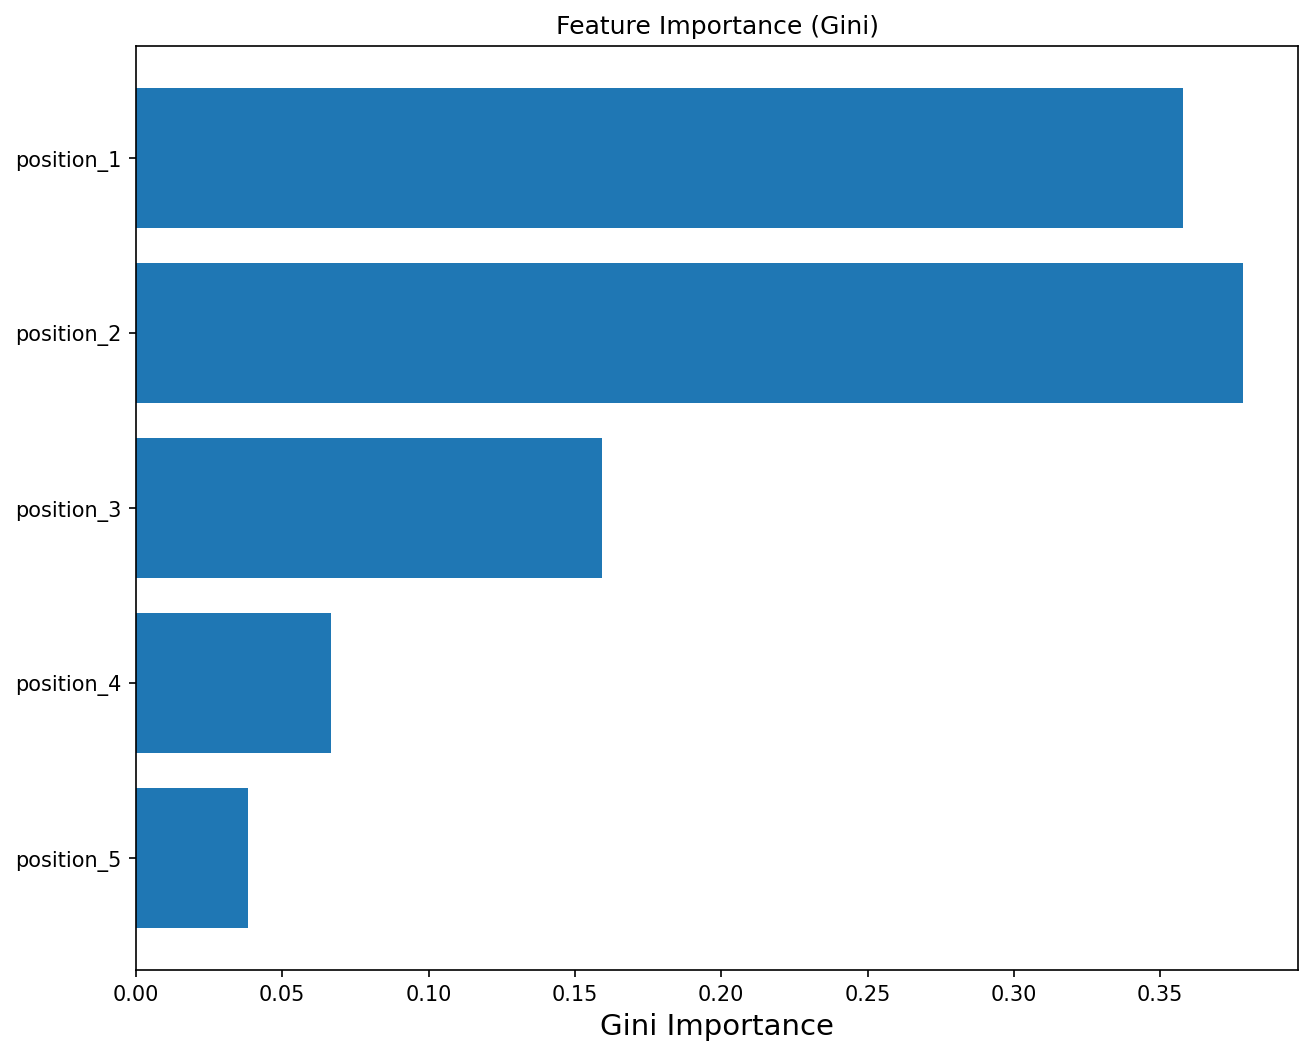

In [14]:
plt.figure(figsize=(10,8),dpi=150)
plt.barh(feature_names, importances)
plt.xlabel('Gini Importance',fontsize=14)
plt.title('Feature Importance (Gini)')
plt.gca().invert_yaxis()
plt.savefig('cy3-eeip-rf-feature-importance.png')
#plt.show()

## Polynomial

In [15]:
with open('../../results/regression/trials/poly_random_forest/cy3_poly_random_forest_eeip_4_trials.pkl', 'rb') as infile:
    trial = pickle.load(infile)

In [16]:
best_indices = trial.argmin
best_params = space_eval(rf_space, best_indices)

In [17]:
rf = RandomForestRegressor(**best_params)

In [18]:
poly = PolynomialFeatures(2, interaction_only=True)
X_train = poly.fit_transform(X_train)
X_test = poly.fit_transform(X_test)

In [19]:
rf.fit(X_train, y_train)

,n_estimators,250
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [20]:
r2 = rf.score(X_test,y_test)

In [21]:
r2

0.8378683328414713

In [22]:
original_feature_names = ['position_1','position_2','position_3','position_4','position_5']
feature_names = poly.get_feature_names_out(original_feature_names)

In [23]:
importances = rf.feature_importances_

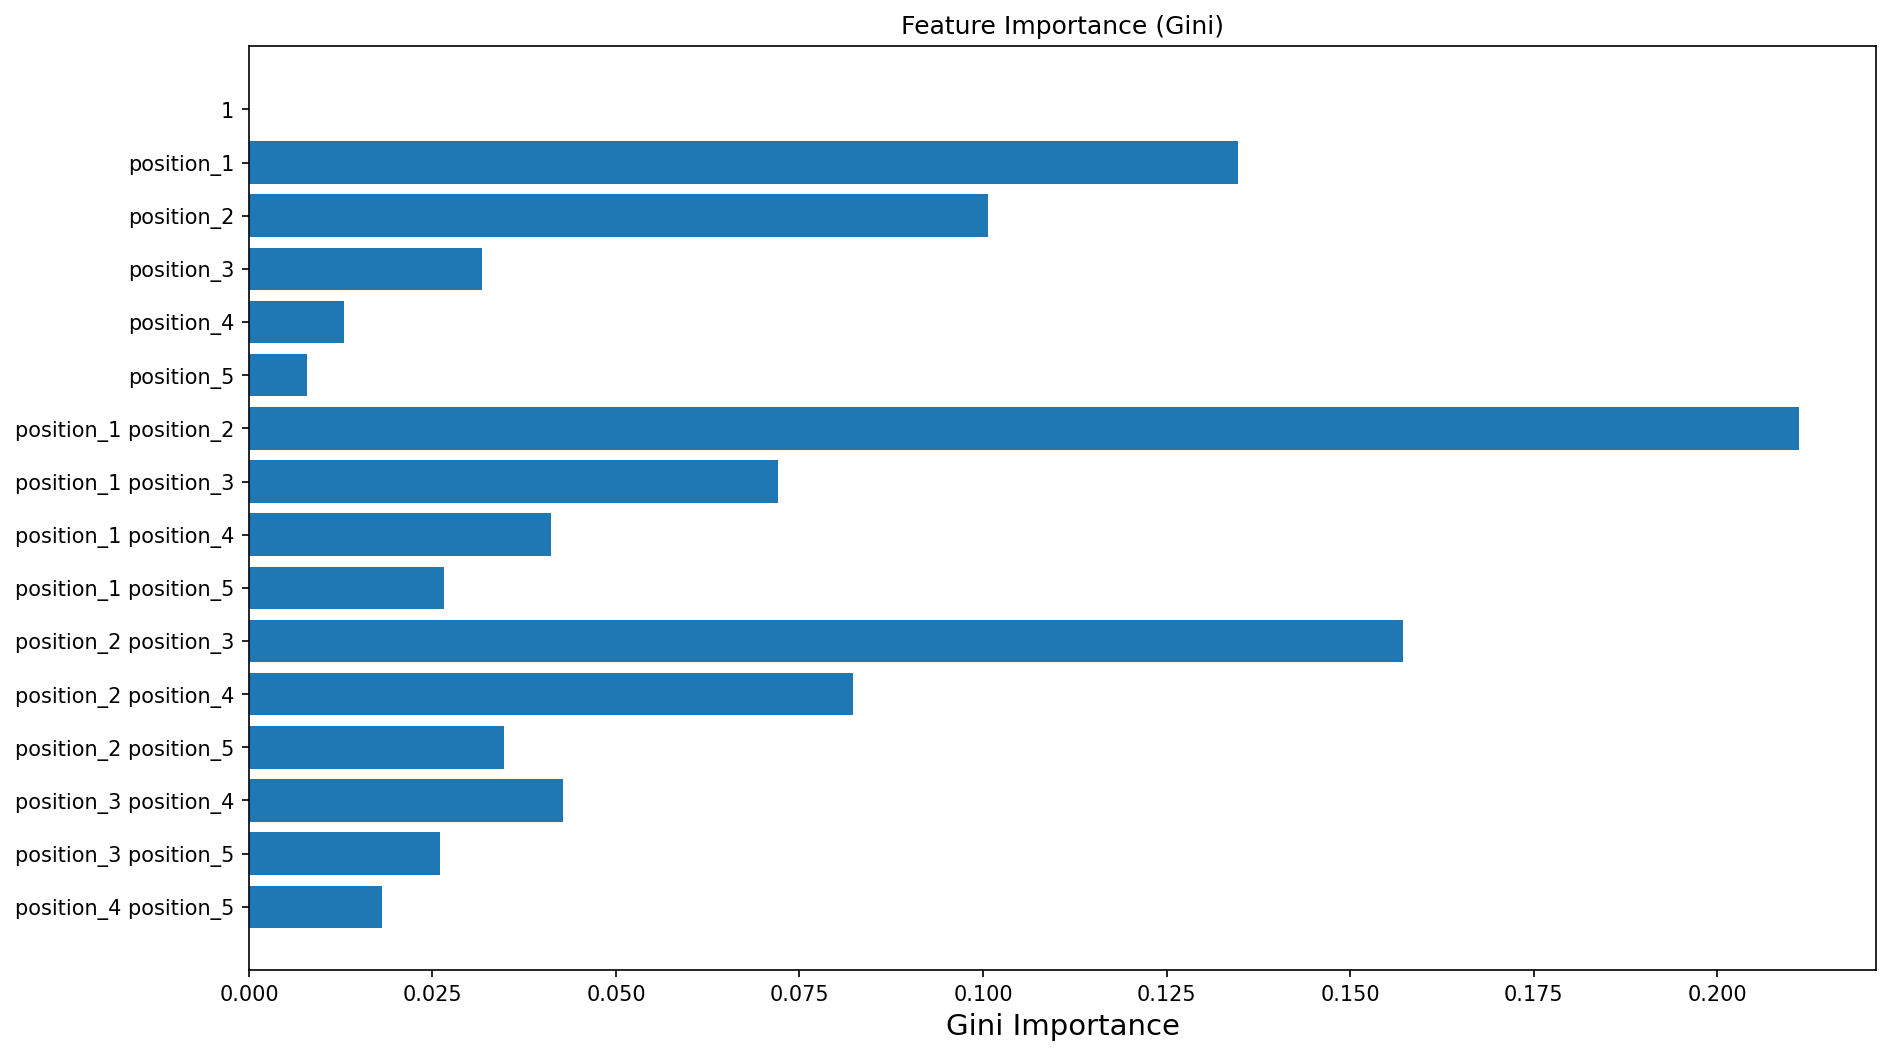

In [24]:
plt.figure(figsize=(14,8),dpi=150)
plt.barh(feature_names, importances)
plt.xlabel('Gini Importance',fontsize=14)
plt.title('Feature Importance (Gini)')
plt.gca().invert_yaxis()
plt.savefig('cy3-poly-eei-rf-feature-importance.png')
#plt.show()

# Cy5

In [26]:
df_cy5 = pd.read_csv('../../data/3_prime_Cy3.csv')

In [27]:
with open('../../results/regression/trials/random_forest/cy5_random_forest_eeip_6_trials.pkl', 'rb') as infile:
    trial = pickle.load(infile)

In [28]:
best_indices = trial.argmin
best_params = space_eval(rf_space, best_indices)

In [29]:
rf = RandomForestRegressor(**best_params)

In [30]:
transformed_df = sequence_transform(dataset=df_cy5, mapping=eeip_mapping,
                                sequence_column_idx=0,intensity_column_idx=1)

X_train, X_test, y_train, y_test = train_test_split(transformed_df.iloc[:,:-1], 
                                                                    transformed_df.iloc[:,-1],
                                                                    test_size=0.30, random_state=42)

In [31]:
rf.fit(X_train, y_train)

,n_estimators,250
,criterion,'absolute_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
r2 = rf.score(X_test,y_test)

In [33]:
r2

0.8068845662976062

In [34]:
importances = rf.feature_importances_
feature_names = ['position_1','position_2','position_3','position_4','position_5']

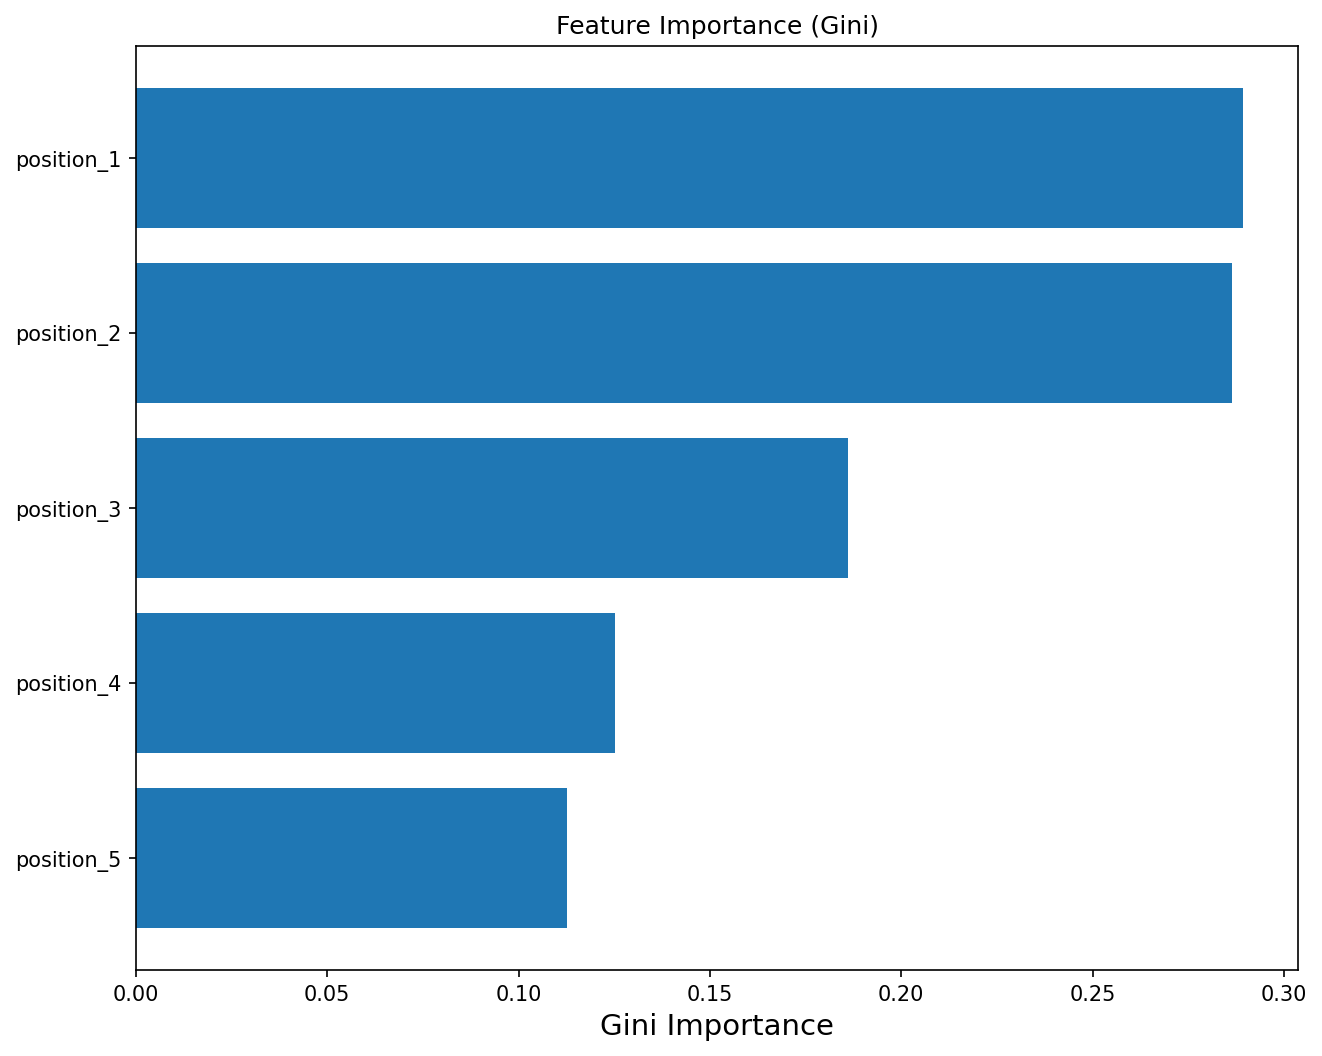

In [36]:
plt.figure(figsize=(10,8),dpi=150)
plt.barh(feature_names, importances)
plt.xlabel('Gini Importance',fontsize=14)
plt.title('Feature Importance (Gini)')
plt.gca().invert_yaxis()
#plt.savefig('cy5_eeip_rf_feature_importance.png')
#plt.show()

## Polynomial

In [37]:
with open('../../results/regression/trials/poly_random_forest/cy5_poly_random_forest_eeip_4_trials.pkl', 'rb') as infile:
    trial = pickle.load(infile)

In [38]:
best_indices = trial.argmin
best_params = space_eval(rf_space, best_indices)

In [39]:
rf = RandomForestRegressor(**best_params)

In [40]:
poly = PolynomialFeatures(2, interaction_only=True)
X_train = poly.fit_transform(X_train)
X_test = poly.fit_transform(X_test)

In [41]:
rf.fit(X_train, y_train)

,n_estimators,250
,criterion,'poisson'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
r2 = rf.score(X_test,y_test)

In [43]:
r2

0.8384539000433224

In [44]:
original_feature_names = ['position_1','position_2','position_3','position_4','position_5']
feature_names = poly.get_feature_names_out(original_feature_names)

In [45]:
importances = rf.feature_importances_

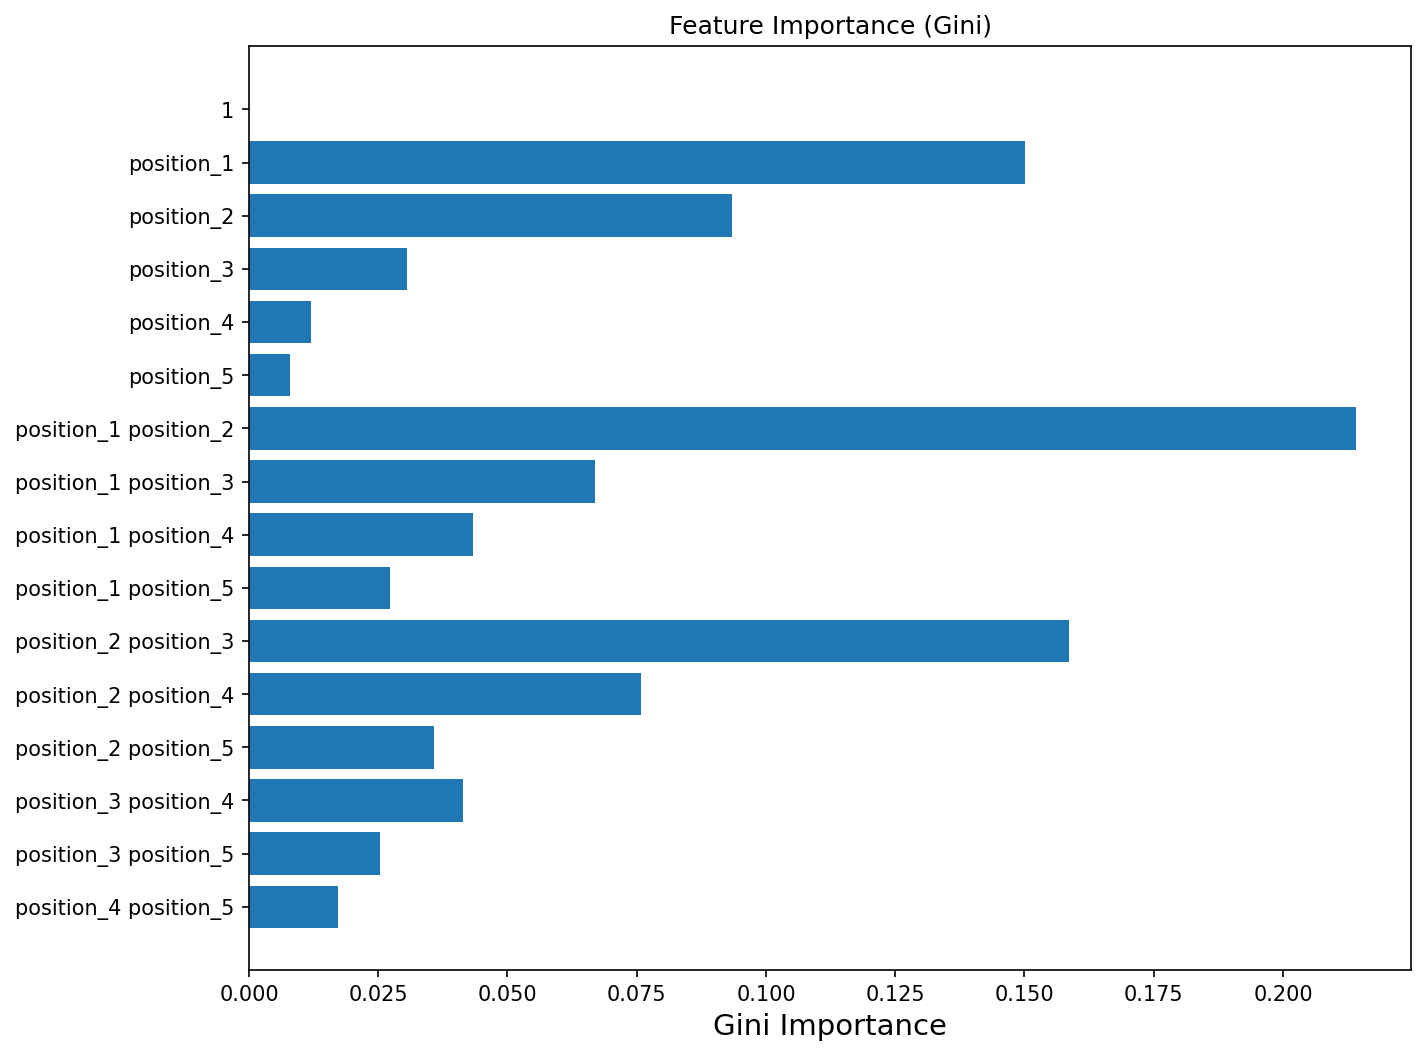

In [47]:
plt.figure(figsize=(10,8),dpi=150)
plt.barh(feature_names, importances)
plt.xlabel('Gini Importance',fontsize=14)
plt.title('Feature Importance (Gini)')
plt.gca().invert_yaxis()
plt.savefig('cy5_poly_rf_feature_importance.png')
#plt.show()